# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3388 Трунов Б.Г. Вариант №19.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

### 1. Линейные дискретные системы

Линейная дискретная система (ЛДС) с нулевыми начальными условиями полностью описывается импульсной характеристикой $h(n)$ (реакцией на единичный импульс $u_0(n)$). Для рекурсивного звена 2-го порядка разностное уравнение имеет вид

$$a_0 y(n) + a_1 y(n-1) + a_2 y(n-2) = b_0 x(n) + b_1 x(n-1) + b_2 x(n-2),$$

а при $a_0 = 1$

$$y(n) = b_0 x(n) + b_1 x(n-1) + b_2 x(n-2) - a_1 y(n-1) - a_2 y(n-2).$$

Z-преобразование при нулевых начальных условиях даёт передаточную функцию

$$H(z) = \frac{b_0 + b_1 z^{-1} + b_2 z^{-2}}{a_0 + a_1 z^{-1} + a_2 z^{-2}}.$$

**Свёртка.** Реакцию на произвольное воздействие можно найти по формуле
$$y(n) = \sum_{m=-\infty}^{\infty} x(m)\,h(n-m).$$
Длина линейной свёртки последовательностей длиной $N_1$ и $N_2$ равна $N_1 + N_2 - 1$.

**Нули и полюсы** - корни числителя и знаменателя $H(z)$. Их можно записать в алгебраической ($z = x + jy$) и показательной ($z = |z|e^{j\varphi}$) формах. Причинная система с рациональной $H(z)$ **устойчива**, если все полюсы лежат строго внутри единичной окружности ($|p| < 1$).

**Частотные характеристики** получаются подстановкой $z = e^{j\hat\omega}$: модуль $|H(e^{j\hat\omega})|$ - АЧХ, аргумент - ФЧХ. Нормированная частота связана с частотой в герцах соотношением $\hat\omega = 2\pi f / f_д$, т.е. $f = \dfrac{\hat\omega}{2\pi} f_д$. Основная полоса: $0 \le \hat\omega \le \pi$ ($0 \le f \le f_д/2$).

### 2. Дискретное преобразование Фурье (ДПФ)

Для последовательности длины (периода) $N$:

$$X(k) = \sum_{n=0}^{N-1} x(n) e^{-j\frac{2\pi}{N}kn}, \qquad x(n) = \frac{1}{N}\sum_{k=0}^{N-1} X(k) e^{j\frac{2\pi}{N}kn}.$$

* **Амплитудный спектр** $|X(k)|$ и **фазовый спектр** $\arg X(k)$ показывают амплитуды и начальные фазы гармоник.
* Шкалы: дискретная частота $k$; нормированная частота $\hat\omega_k = 2\pi k/N$ (или $k/N$); абсолютная частота $f_k = k f_д / N$. Аналогично для времени: $n$, $n/N$, $t = nT$.
* Коэффициенты ряда Фурье периодической последовательности $C(k) = X(k)/N$, поэтому $|X(k)| = N\,|C(k)|$.
* **Восстановление аналогового сигнала** по отсчётам ДПФ выполняется рядом Фурье
$$x(t) = \frac{1}{N}\sum_{k=-N/2}^{N/2-1} X_a(k)\, e^{j\frac{2\pi k t}{NT}},$$
где $X_a(k) = X(N+k)$ при $-N/2 \le k < 0$ и $X_a(k) = X(k)$ при $0 \le k \le N/2-1$. Точное восстановление возможно при выполнении условия теоремы Котельникова ($f_д > 2 f_{max}$).
* **Равенство Парсеваля** (закон сохранения энергии):
$$\sum_{n=0}^{N-1} |x(n)|^2 = \frac{1}{N}\sum_{k=0}^{N-1} |X(k)|^2.$$

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

**Часть 1.** Импульсная характеристика, реакция на прямоугольный импульс (свёртка и разностное уравнение), нули и полюсы, карта нулей и полюсов, АЧХ и ФЧХ в нормированных частотах и в герцах.

**Часть 2.** Амплитудный и фазовый спектры периодической последовательности, ОДПФ, ДПФ конечной последовательности и сравнение со спектром периодической, восстановление аналогового сигнала, проверка равенства Парсеваля.

## Выполнение работы

### Импорт библиотек и параметры варианта 19

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import freqz, tf2zpk, lfilter

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

N_var = 19

# часть 1 
b0 = 0.5 + 0.02 * N_var
b1 = b0 * (-1) ** (N_var + 1) * (0.9822 + 0.0178 * N_var)
b2 = b0 * (0.8 + 0.2 * (N_var % 5))
a0 = 1.0
a1 = (-1) ** N_var * (0.7778 + 0.025 * N_var)
a2 = 0.64 + 0.006 * N_var
N1 = N_var % 10 + 20    # длина импульсной характеристики
N2 = N_var % 10 + 30    # длина воздействия
fd1 = 1000.0 * N_var    # частота дискретизации, Гц

b = np.array([b0, b1, b2])
a = np.array([a0, a1, a2])

# часть 2
N = 64
fd2 = 2000.0 * (N_var % 5 + 1)
T = 1.0 / fd2
A1 = 1 + 0.01 * N_var
A2 = 2 * A1
f1 = fd2 / 8
f2 = 1.5 * f1

print("Часть 1")
print(f"b = {b}")
print(f"a = {a}")
print(f"N1 = {N1}, N2 = {N2}, fд = {fd1:.0f} Гц")
print("Часть 2")
print(f"N = {N}, fд = {fd2:.0f} Гц, T = {T:.1e} с")
print(f"A1 = {A1}, A2 = {A2}, f1 = {f1:.0f} Гц, f2 = {f2:.0f} Гц")

Часть 1
b = [0.88     1.161952 1.408   ]
a = [ 1.     -1.2528  0.754 ]
N1 = 29, N2 = 39, fд = 19000 Гц
Часть 2
N = 64, fд = 10000 Гц, T = 1.0e-04 с
A1 = 1.19, A2 = 2.38, f1 = 1250 Гц, f2 = 1875 Гц


## Часть 1. Линейные дискретные системы

### Пункт 1.1. Импульсная характеристика

Импульсная характеристика считается двумя независимыми способами: непосредственно рекурсией по разностному уравнению при $x(n) = u_0(n)$ и функцией `lfilter`. Совпадение двух результатов служит проверкой.

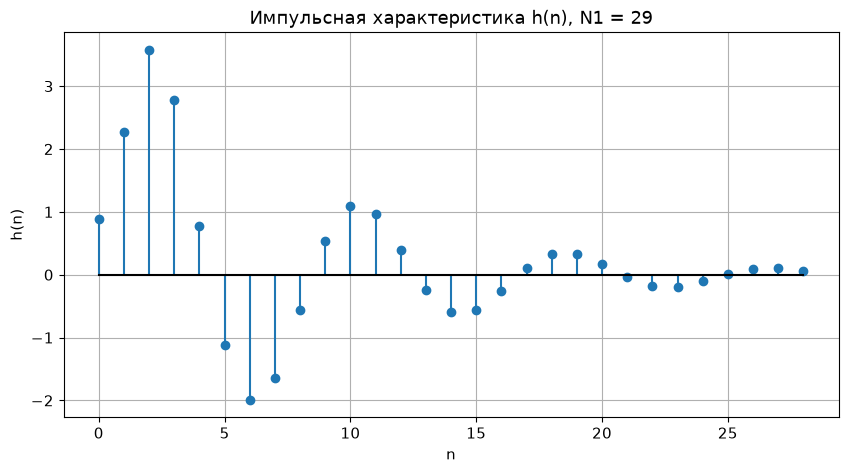

  n   h(n)
  0   0.88000000
  1   2.26441600
  2   3.58134036
  3   2.77933355
  4   0.78161843
  5  -1.11640592
  6  -1.98797364
  7  -1.64876331
  8  -0.56663855
  9   0.53328276
 10   1.09534211
 11   0.97014939
 12   0.38951521
 13  -0.24350799
 14  -0.59876127
 15  -0.56652310
 16  -0.25827414
 17   0.10359258
 18   0.32451948
 19   0.32844920
 20   0.16679347
 21  -0.03869184
 22  -0.17423541
 23  -0.18910848
 24  -0.10554160
 25   0.01036527
 26   0.09256398
 27   0.10814874
 28   0.06569550

Аналитическая формула совпадает с рекурсией (макс. разность 1.1e-15)
|h(N1-1)| / max|h| = 0.0183
|h(n)| < 1% от максимума при n >= 33, < 0.1% при n >= 49


In [ ]:
def impulse_response_recursive(b, a, n_samples):
    """h(n) по разностному уравнению при x(n) = u0(n), нулевые начальные условия."""
    h = np.zeros(n_samples)
    for n in range(n_samples):
        v = b[n] if n < len(b) else 0.0 # вклад входа: x(n-k) = u0(n-k)
        for k in (1, 2):
            if n - k >= 0:
                v -= a[k] * h[n - k]
        h[n] = v / a[0]
    return h

h = impulse_response_recursive(b, a, N1)

delta = np.zeros(N1); delta[0] = 1.0
assert np.allclose(h, lfilter(b, a, delta))

plt.figure()
plt.stem(np.arange(N1), h, basefmt="k-")
plt.xlabel("n"); plt.ylabel("h(n)")
plt.title(f"Импульсная характеристика h(n), N1 = {N1}")
plt.grid(True); plt.show()

print("  n   h(n)")
for n in range(N1):
    print(f"{n:3d}  {h[n]: .8f}")

# аналитическая формула
r = np.sqrt(a2) # модуль полюсов
theta = np.arccos(-a1 / (2 * r))    # аргумент полюса
h1, h2 = h[1], h[2]
C_sin = (h2 / r - h1 * np.cos(theta)) / np.sin(theta)

n_an = np.arange(1, N1)
h_an = r ** (n_an - 1) * (h1 * np.cos((n_an - 1) * theta) + C_sin * np.sin((n_an - 1) * theta))
assert np.allclose(h_an, h[1:]) # формула совпадает с рекурсией при n >= 1
print(f"\nАналитическая формула совпадает с рекурсией (макс. разность {np.max(np.abs(h_an - h[1:])):.1e})")

h_long = lfilter(b, a, np.r_[1.0, np.zeros(999)])
def effective_length(level):
    return np.flatnonzero(np.abs(h_long) >= level * np.max(np.abs(h_long)))[-1] + 1
L_1pct, L_01pct = effective_length(1e-2), effective_length(1e-3)
ratio_end = abs(h[-1]) / np.max(np.abs(h))
print(f"|h(N1-1)| / max|h| = {ratio_end:.4f}")
print(f"|h(n)| < 1% от максимума при n >= {L_1pct}, < 0.1% при n >= {L_01pct}")

Рассчитаны первые $N_1 = 29$ отсчётов импульсной характеристики для $b = [0.8800;\ 1.161952;\ 1.4080]$ и $a = [1;\ -1.2528;\ 0.754]$.

**Разностное уравнение:**
$$y(n) = 0.88\,x(n) + 1.161952\,x(n-1) + 1.408\,x(n-2) + 1.2528\,y(n-1) - 0.754\,y(n-2).$$

**Аналитическая формула.** Знаменатель $z^2 - 1.2528 z + 0.754$ имеет комплексно-сопряжённые корни $p_{1,2} = r e^{\pm j\theta}$, $r = \sqrt{a_2} = 0.8683$, $\theta = 0.7650$ рад $= 0.2435\pi$. Из рекурсии $h(0) = b_0 = 0.8800$, $h(1) = b_1 - a_1 h(0) = 2.264416$, $h(2) = b_2 - a_1 h(1) - a_2 h(0) = 3.581340$, а при $n \ge 3$ уравнение однородно: $h(n) = -a_1 h(n-1) - a_2 h(n-2)$. Поэтому при $n \ge 1$

$$h(n) = r^{\,n-1}\Big[\,h(1)\cos\big((n-1)\theta\big) + C\sin\big((n-1)\theta\big)\Big], \qquad C = \frac{h(2)/r - h(1)\cos\theta}{\sin\theta} = 3.5968,$$

то есть
$$h(0) = 0.88, \qquad h(n) = 0.8683^{\,n-1}\Big[2.2644\cos\big(0.7650(n-1)\big) + 3.5968\sin\big(0.7650(n-1)\big)\Big],\ n \ge 1.$$

Cистема рекурсивная (БИХ), $h(n)$ затухает как $r^n$, но ни при каком $n$ не обращается в ноль, а полюсы не сокращаются нулями. Благодаря устойчивости ($r = 0.8683 < 1$) отсчёты убывают, но к $n = N_1 - 1$ значение $|h|$ составляет ещё 1.8 % от максимума, а ниже 1 % оно опускается только при $n \ge 33$ (ниже 0.1 % — при $n \ge 49$). Поэтому длина $N_1 = 29$ — это заданное практическое ограничение, а не точка, где $h(n)$ становится нулём,последствия усечения видны в пунктах 1.2 и 1.3.

### Пункт 1.2. Реакция по формуле свёртки

Воздействие - прямоугольный импульс длины $N_2$: первые $\text{int}(N_2/2 + 0.5)$ отсчётов равны единице, остальные нулю. Свёртка считается с первыми $N_1$ отсчётами $h(n)$ из п. 1.1.

Длина воздействия x(n): 39 (из них единиц: 20)
Длина h(n): 29
Длина свёртки по формуле: N2 + N1 - 1 = 67
Последний ненулевой отсчёт: n = 47 => ненулевая часть 48 отсчётов
Длина y1(n) после ограничения: 39


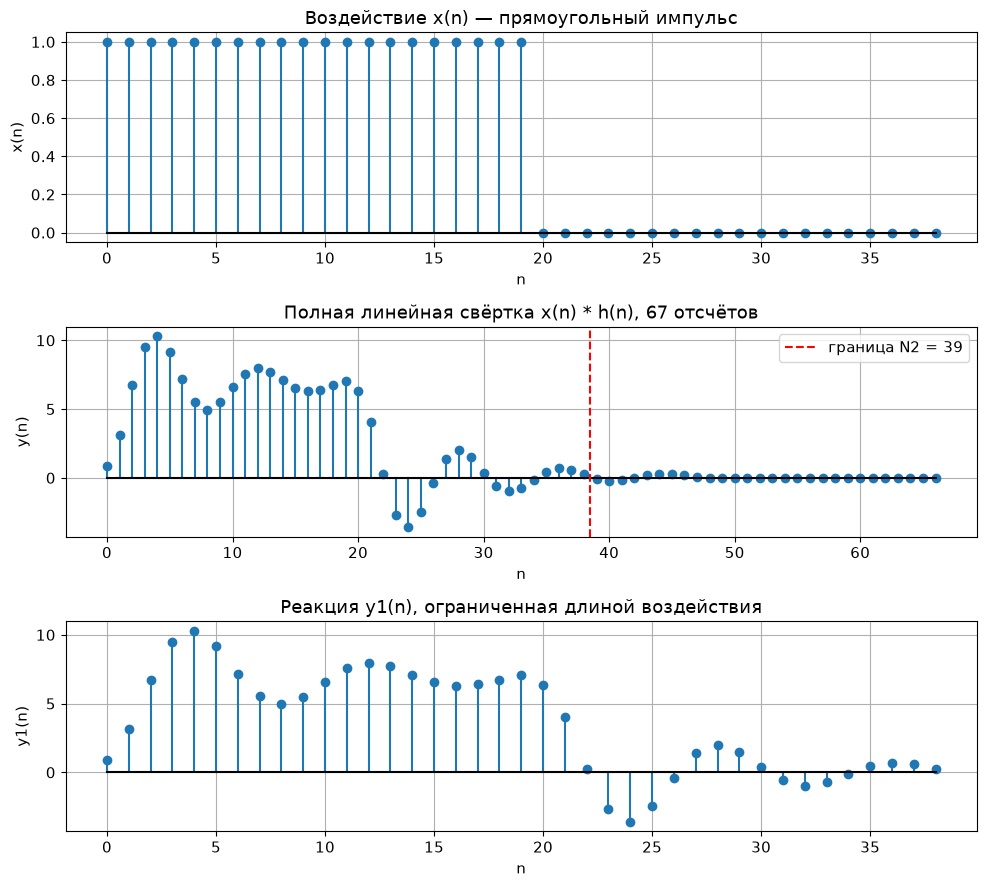

In [107]:
pulse_length = int(N2 / 2 + 0.5) # число единичных отсчётов
x = np.zeros(N2)
x[:pulse_length] = 1.0
n_x = np.arange(N2)

y_full = np.convolve(x, h)  # полная линейная свёртка
y1 = y_full[:N2]    # реакция, ограниченная длиной воздействия

last_nonzero = np.flatnonzero(np.abs(y_full) > 1e-12)[-1]
print(f"Длина воздействия x(n): {len(x)} (из них единиц: {pulse_length})")
print(f"Длина h(n): {len(h)}")
print(f"Длина свёртки по формуле: N2 + N1 - 1 = {N2 + N1 - 1}")
print(f"Последний ненулевой отсчёт: n = {last_nonzero} => ненулевая часть {last_nonzero + 1} отсчётов")
print(f"Длина y1(n) после ограничения: {len(y1)}")

fig, axes = plt.subplots(3, 1, figsize=(10, 9))
axes[0].stem(n_x, x, basefmt="k-")
axes[0].set_title("Воздействие x(n) — прямоугольный импульс")
axes[0].set_xlabel("n"); axes[0].set_ylabel("x(n)"); axes[0].grid(True)

axes[1].stem(np.arange(len(y_full)), y_full, basefmt="k-")
axes[1].axvline(N2 - 0.5, color="r", ls="--", label=f"граница N2 = {N2}")
axes[1].set_title(f"Полная линейная свёртка x(n) * h(n), {len(y_full)} отсчётов")
axes[1].set_xlabel("n"); axes[1].set_ylabel("y(n)"); axes[1].legend(); axes[1].grid(True)

axes[2].stem(n_x, y1, basefmt="k-")
axes[2].set_title("Реакция y1(n), ограниченная длиной воздействия")
axes[2].set_xlabel("n"); axes[2].set_ylabel("y1(n)"); axes[2].grid(True)
plt.tight_layout(); plt.show()

**а) Длина воздействия** $x(n)$ равна $N_2 = 39$ отсчётам, из которых $20$ единичные ($n = 0, \dots, 19$), остальные нулевые.

**б) Длина свёртки.** *Аналитически:* $N_2 + N_1 - 1 = 39 + 29 - 1 = 67$ отсчёта. *По графику:* ненулевая часть свёртки заканчивается на $n = 47$, т.е. занимает $48$ отсчётов — это сумма индексов последних ненулевых отсчётов входа ($19$) и $h(n)$ ($28$). Остальные отсчёты до $n = 66$ нулевые.

**в) Почему реакцию ограничивают длиной воздействия?** После окончания входного сигнала рекурсивное звено продолжает «звенеть» — свободные затухающие колебания, вызванные ранее поступившим сигналом (память звена). Реакцию обычно рассматривают на интервале действия воздействия $0 \le n < N_2$, чтобы сравнивать её с реакцией по разностному уравнению в п. 1.3, где выход вычисляется только для $N_2$ отсчётов. На графике видно: пока $n < 20$, идёт накопление отклика, затем при нулевом входе — затухающие колебания (из-за комплексно-сопряжённых полюсов).

### Пункт 1.3. Реакция по разностному уравнению

Макс. |y1 - y2| (h усечена до N1 = 29):       1.538e-01
Первый отсчёт с расхождением:                  n = 29
Макс. |y1 - y2| при h длиной N2 = 39:          2.665e-15


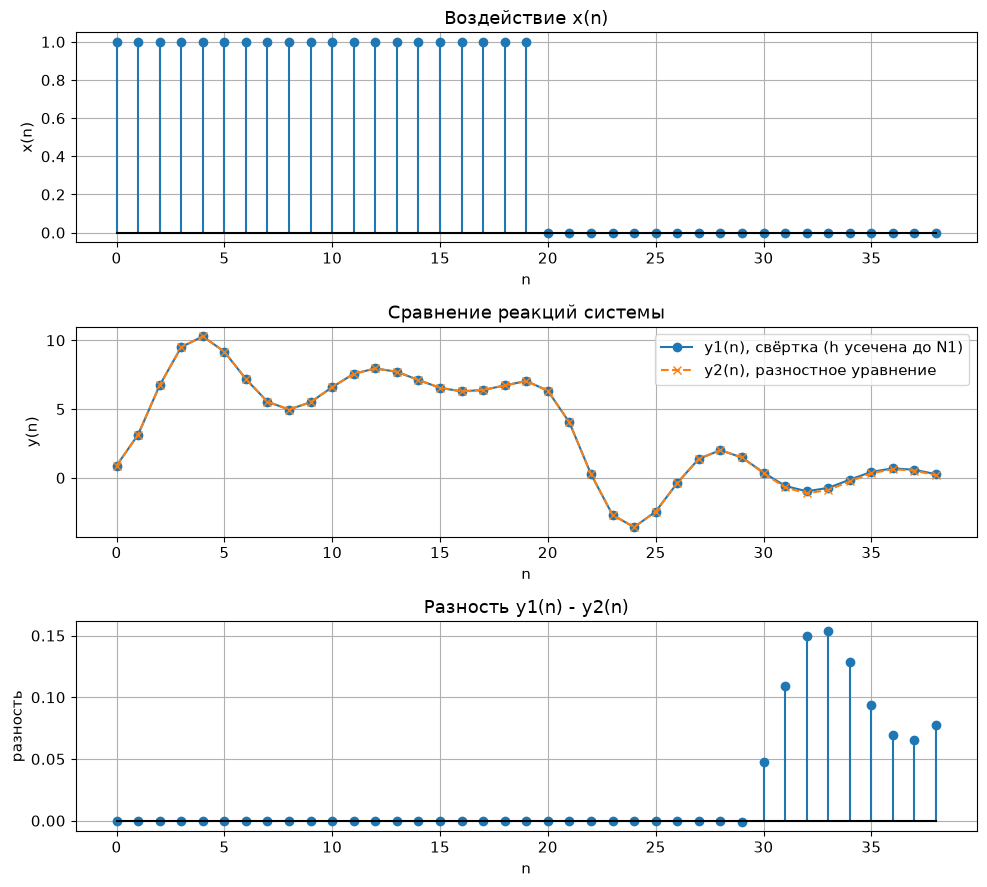

In [108]:
def filter_recursive(b, a, x):
    """Вычисление y(n) по разностному уравнению."""
    y = np.zeros(len(x))
    for n in range(len(x)):
        acc = sum(b[k] * x[n - k] for k in range(len(b)) if n - k >= 0)
        acc -= sum(a[k] * y[n - k] for k in (1, 2) if n - k >= 0)
        y[n] = acc / a[0]
    return y

y2 = filter_recursive(b, a, x)
assert np.allclose(y2, lfilter(b, a, x))

diff = y1 - y2
max_diff = np.max(np.abs(diff))
first_bad = np.flatnonzero(np.abs(diff) > 1e-12)[0]

# Проверка расхождения: свёртка с h(n) длиной N2 (без усечения до N1)
h_N2 = lfilter(b, a, np.r_[1.0, np.zeros(N2 - 1)])
y1_ext = np.convolve(x, h_N2)[:N2]
max_diff_ext = np.max(np.abs(y1_ext - y2))

print(f"Макс. |y1 - y2| (h усечена до N1 = {N1}):       {max_diff:.3e}")
print(f"Первый отсчёт с расхождением:                  n = {first_bad}")
print(f"Макс. |y1 - y2| при h длиной N2 = {N2}:          {max_diff_ext:.3e}")

fig, axes = plt.subplots(3, 1, figsize=(10, 9))
axes[0].stem(n_x, x, basefmt="k-")
axes[0].set_title("Воздействие x(n)")
axes[0].set_xlabel("n"); axes[0].set_ylabel("x(n)"); axes[0].grid(True)

axes[1].plot(n_x, y1, "o-", label="y1(n), свёртка (h усечена до N1)")
axes[1].plot(n_x, y2, "x--", label="y2(n), разностное уравнение")
axes[1].set_title("Сравнение реакций системы")
axes[1].set_xlabel("n"); axes[1].set_ylabel("y(n)"); axes[1].legend(); axes[1].grid(True)

axes[2].stem(n_x, diff, basefmt="k-")
axes[2].set_title("Разность y1(n) - y2(n)")
axes[2].set_xlabel("n"); axes[2].set_ylabel("разность"); axes[2].grid(True)
plt.tight_layout(); plt.show()

**Разностное уравнение** (с найденными коэффициентами):
$$y_2(n) = 0.88\,x(n) + 1.161952\,x(n-1) + 1.408\,x(n-2) + 1.2528\,y_2(n-1) - 0.754\,y_2(n-2).$$

**Длины.** Воздействие $x(n)$ имеет длину $N_2 = 39$; реакция $y_2(n)$ вычислена на тех же $N_2 = 39$ отсчётах. Теоретически отклик рекурсивного звена продолжается бесконечно (затухая), но рассматривается на интервале действия воздействия.

**Сравнение $y_1(n)$ и $y_2(n)$.** Реакции совпадают на отсчётах $n = 0, \dots, 28$. Начиная с $n = 29 = N_1$ появляется расхождение, максимальная абсолютная разность равна $0.1538$. Это **не** ошибка округления: при вычислении $y_1(n)$ использованы только первые $N_1$ отсчётов $h(n)$. Пока $n < N_1$, остальные значения $h$ в сумму не входят, а при $n \ge N_1$ они уже вносят вклад — и усечение даёт погрешность. Таким образом, $y_1$ — приближение с усечённой характеристикой, а $y_2$ — точная реакция рекурсивного звена.

Подтверждение причины: если выполнить свёртку с характеристикой длиной $N_2$ (достаточной, чтобы покрыть весь интервал $0 \le n < N_2$), расхождение исчезает: $\max|y_1 - y_2| = 2.66e-15$ — машинный ноль. Следовательно, свёртка и разностное уравнение — эквивалентные способы получения реакции ЛДС, различие вызвано только конечной длиной $h(n)$.

### Пункт 1.4. Нули и полюсы передаточной функции

In [97]:
zeros, poles, k_gain = tf2zpk(b, a)
zeros = sorted(zeros, key=lambda v: v.imag, reverse=True)
poles = sorted(poles, key=lambda v: v.imag, reverse=True)
zeros, poles = np.array(zeros), np.array(poles)

def show(name, roots):
    for i, v in enumerate(roots, 1):
        print(f"{name}{i} = {v.real:+.6f} {v.imag:+.6f}j | модуль = {abs(v):.6f}, "
              f"аргумент = {np.angle(v):+.6f} рад = {np.angle(v)/np.pi:+.6f}·π")

print("Нули:");   show("z", zeros)
print("Полюсы:"); show("p", poles)
print(f"Коэффициент усиления k = {k_gain:.6f}")

# проверка: полиномы восстанавливаются по корням
assert np.allclose(k_gain * np.poly(zeros), b)
assert np.allclose(np.poly(poles), a)

Нули:
z1 = -0.660200 +1.078951j | модуль = 1.264911, аргумент = +2.119913 рад = +0.674789·π
z2 = -0.660200 -1.078951j | модуль = 1.264911, аргумент = -2.119913 рад = -0.674789·π
Полюсы:
p1 = +0.626400 +0.601351j | модуль = 0.868332, аргумент = +0.764999 рад = +0.243507·π
p2 = +0.626400 -0.601351j | модуль = 0.868332, аргумент = -0.764999 рад = -0.243507·π
Коэффициент усиления k = 0.880000


Умножая числитель и знаменатель на $z^2$, получаем
$$H(z) = \frac{0.88 z^2 + 1.161952 z + 1.408}{z^2 - 1.2528 z + 0.754}.$$
Нули — корни числителя, полюсы — корни знаменателя. Так как коэффициенты вещественны, корни образуют комплексно-сопряжённые пары. Связь форм записи: $x = |z|\cos\varphi$, $y = |z|\sin\varphi$, $|z| = \sqrt{x^2 + y^2}$, $\varphi = \operatorname{arg} z$.

| Корень | Алгебраическая форма | Модуль | Аргумент, рад | Аргумент, доли $\pi$ |
| :--- | :--- | :--- | :--- | :--- |
| Нуль $z_1$ | $-0.6602 + j1.0790$ | $1.2649$ | $2.1199$ | $0.6748\pi$ |
| Нуль $z_2$ | $-0.6602 - j1.0790$ | $1.2649$ | $-2.1199$ | $-0.6748\pi$ |
| Полюс $p_1$ | $0.6264 + j0.6014$ | $0.8683$ | $0.7650$ | $0.2435\pi$ |
| Полюс $p_2$ | $0.6264 - j0.6014$ | $0.8683$ | $-0.7650$ | $-0.2435\pi$ |

**Показательная форма:**
$z_{1,2} = 1.2649\,e^{\pm j 0.6748\pi}$, $\quad p_{1,2} = 0.8683\,e^{\pm j 0.2435\pi}$.

**Передаточная функция в виде произведения простейших множителей** ($k = b_0 = 0.88$):
$$H(z) = 0.88\;\frac{\left(1 - 1.2649 e^{j 0.6748\pi} z^{-1}\right)\left(1 - 1.2649 e^{-j 0.6748\pi} z^{-1}\right)}{\left(1 - 0.8683 e^{j 0.2435\pi} z^{-1}\right)\left(1 - 0.8683 e^{-j 0.2435\pi} z^{-1}\right)}.$$

Корректность найденных корней проверена в коде: полиномы, построенные по нулям и полюсам, совпадают с исходными коэффициентами.

### Пункт 1.5. Карта нулей и полюсов

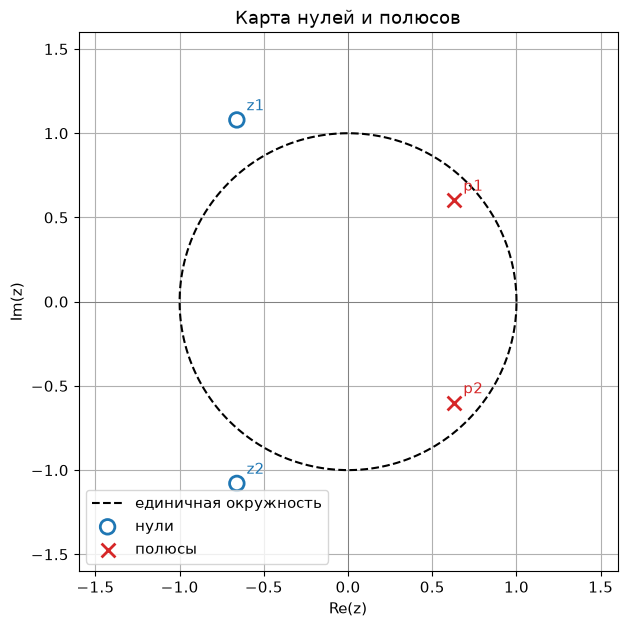

Модули полюсов: 0.868332, 0.868332
Система устойчива: True


In [98]:
fig, ax = plt.subplots(figsize=(7, 7))
th = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(th), np.sin(th), "k--", label="единичная окружность")
ax.scatter(zeros.real, zeros.imag, marker="o", s=110, facecolors="none",
           edgecolors="tab:blue", linewidths=2, label="нули")
ax.scatter(poles.real, poles.imag, marker="x", s=100, color="tab:red", linewidths=2, label="полюсы")
for i, v in enumerate(zeros, 1):
    ax.annotate(f"z{i}", (v.real, v.imag), xytext=(7, 7), textcoords="offset points", color="tab:blue")
for i, v in enumerate(poles, 1):
    ax.annotate(f"p{i}", (v.real, v.imag), xytext=(7, 7), textcoords="offset points", color="tab:red")
ax.axhline(0, color="gray", lw=0.7); ax.axvline(0, color="gray", lw=0.7)
ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6); ax.set_aspect("equal")
ax.set_xlabel("Re(z)"); ax.set_ylabel("Im(z)")
ax.set_title("Карта нулей и полюсов"); ax.legend(loc="lower left"); ax.grid(True)
plt.show()

pole_radii = np.abs(poles)
stable = bool(np.all(pole_radii < 1))
print("Модули полюсов:", ", ".join(f"{v:.6f}" for v in pole_radii))
print("Система устойчива:", stable)

Синие кружки — нули, красные крестики — полюсы, штриховая линия — единичная окружность (граница устойчивости).

**а) Устойчивость.** Оба полюса лежат внутри единичной окружности: $|p_{1,2}| = 0.8683 < 1$. Следовательно, рекурсивное звено **устойчиво**. Нули ($|z| = 1.2649 > 1$) лежат вне окружности; на устойчивость это не влияет, но означает, что АЧХ нигде не обращается в ноль.

**б) Сравнение с п. 1.4.** Координаты маркеров совпадают с рассчитанными: нули $-0.6602 \pm j1.0790$ (левая полуплоскость), полюсы $0.6264 \pm j0.6014$ (правая полуплоскость).

### Пункт 1.6. АЧХ и ФЧХ в шкале нормированных частот

|H| при ω=0:       6.8834
|H| при ω=π:       0.3745
Максимум АЧХ:      16.7881 при ω/π = 0.2369
Минимум АЧХ:       0.2019 при ω/π = 0.6927
Угол полюса / π:   0.2435,  угол нуля / π: 0.6748
Изменение фазы от 0 до π: -6.2832 рад = -2.0000·π


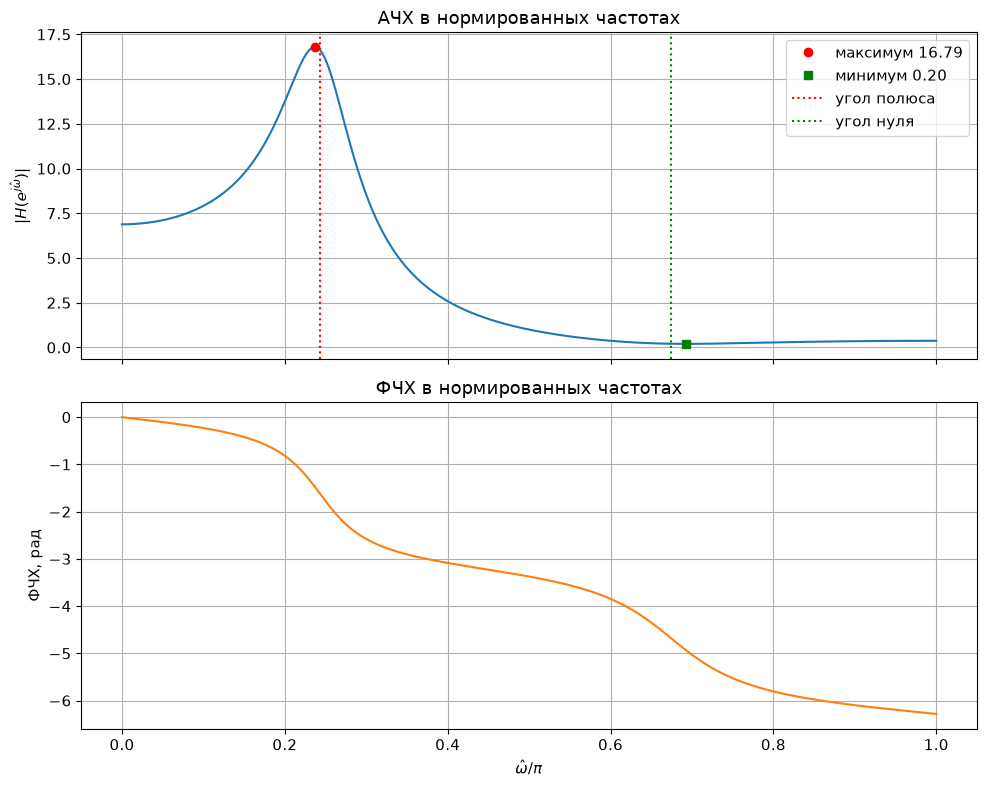

In [99]:
w = np.linspace(0, np.pi, 2048)
_, H = freqz(b, a, worN=w)
amp = np.abs(H)
phase = np.unwrap(np.angle(H))

i_max, i_min = np.argmax(amp), np.argmin(amp)
print(f"|H| при ω=0:       {amp[0]:.4f}")
print(f"|H| при ω=π:       {amp[-1]:.4f}")
print(f"Максимум АЧХ:      {amp[i_max]:.4f} при ω/π = {w[i_max]/np.pi:.4f}")
print(f"Минимум АЧХ:       {amp[i_min]:.4f} при ω/π = {w[i_min]/np.pi:.4f}")
print(f"Угол полюса / π:   {abs(np.angle(poles[0]))/np.pi:.4f},  угол нуля / π: {abs(np.angle(zeros[0]))/np.pi:.4f}")
print(f"Изменение фазы от 0 до π: {phase[-1] - phase[0]:+.4f} рад = {(phase[-1]-phase[0])/np.pi:+.4f}·π")

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
axes[0].plot(w / np.pi, amp)
axes[0].plot(w[i_max] / np.pi, amp[i_max], "ro", label=f"максимум {amp[i_max]:.2f}")
axes[0].plot(w[i_min] / np.pi, amp[i_min], "gs", label=f"минимум {amp[i_min]:.2f}")
axes[0].axvline(abs(np.angle(poles[0])) / np.pi, color="r", ls=":", label="угол полюса")
axes[0].axvline(abs(np.angle(zeros[0])) / np.pi, color="g", ls=":", label="угол нуля")
axes[0].set_ylabel(r"$|H(e^{j\hat\omega})|$"); axes[0].set_title("АЧХ в нормированных частотах")
axes[0].legend(); axes[0].grid(True)

axes[1].plot(w / np.pi, phase, color="tab:orange")
axes[1].set_xlabel(r"$\hat\omega / \pi$"); axes[1].set_ylabel("ФЧХ, рад")
axes[1].set_title("ФЧХ в нормированных частотах"); axes[1].grid(True)
plt.tight_layout(); plt.show()

**а) Основная полоса.** Характеристики периодичны по $\hat\omega$ с периодом $2\pi$, а для вещественных коэффициентов АЧХ чётна, поэтому достаточно полосы $0 \le \hat\omega \le \pi$; $\hat\omega = \pi$ соответствует $f_д/2$.

**б) Связь с картой нулей и полюсов.**
* Резонансный максимум $|H|_{max} = 16.79$ при $\hat\omega \approx 0.237\pi$ создаётся полюсом: его аргумент равен $0.2435\pi$, модуль $0.868$ близок к 1. Чем ближе полюс к окружности, тем выше и острее пик. Максимум немного смещён от угла полюса из-за влияния нулей и второго (сопряжённого) полюса.
* Провал $|H|_{min} = 0.202$ при $\hat\omega \approx 0.693\pi$ создаётся нулём с аргументом $0.6748\pi$. В ноль АЧХ не обращается, так как нули лежат вне окружности ($|z| = 1.265$).

**в) Скачок фазы.** Скачок ФЧХ на $\pi$ соответствует нулю АЧХ, т.е. нулю на единичной окружности. Здесь таких нулей нет ($\min|H| = 0.202 > 0$), поэтому после `unwrap` ФЧХ меняется непрерывно; полное изменение фазы на $[0, \pi]$ равно -6.283 рад.

**г) Подавление частот.** Система усиливает низкие частоты ($|H(0)| = 6.88$, пик 16.8 вблизи $0.24\pi$) и ослабляет высокие ($|H(\pi)| = 0.37 < 1$). Таким образом, звено ведёт себя как резонансный фильтр нижних частот с максимальным подавлением вблизи $0.69\pi$.

### Пункт 1.7. АЧХ и ФЧХ в шкале частот (Гц)

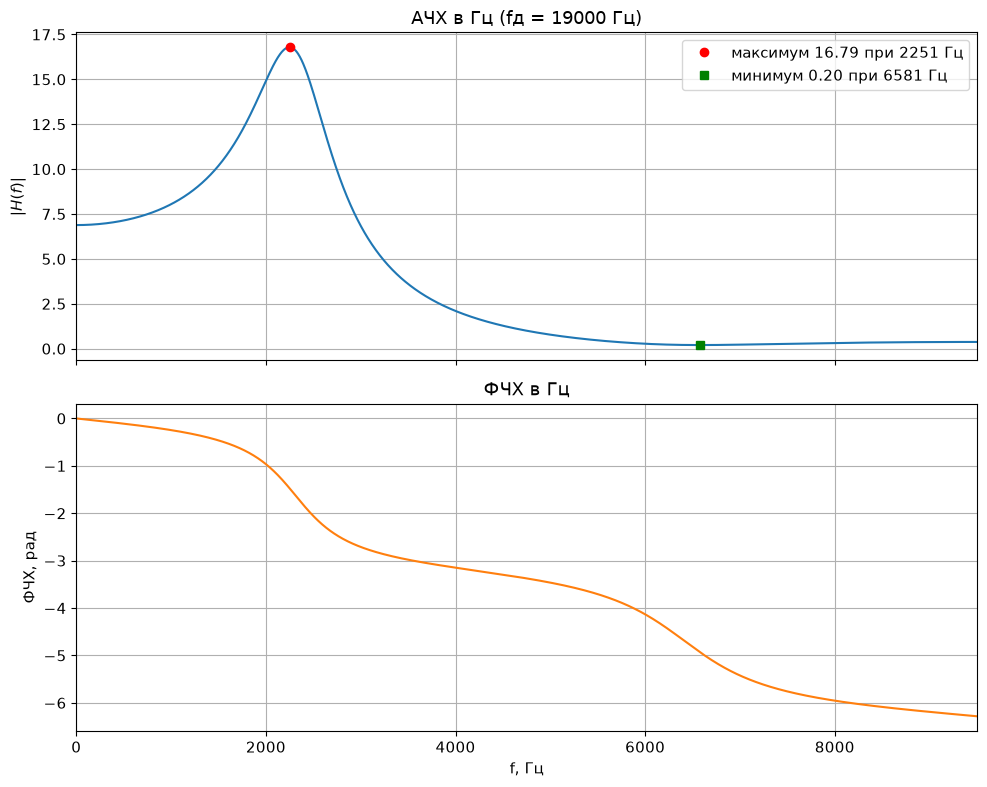

Максимум АЧХ: 16.7881 при f = 2250.9 Гц
Минимум АЧХ:  0.2019 при f = 6580.9 Гц
|H| < 1 при f > 4752 Гц


In [ ]:
f_hz = w * fd1 / (2 * np.pi)       # 0 ... fд/2

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
axes[0].plot(f_hz, amp)
axes[0].plot(f_hz[i_max], amp[i_max], "ro", label=f"максимум {amp[i_max]:.2f} при {f_hz[i_max]:.0f} Гц")
axes[0].plot(f_hz[i_min], amp[i_min], "gs", label=f"минимум {amp[i_min]:.2f} при {f_hz[i_min]:.0f} Гц")
axes[0].set_ylabel(r"$|H(f)|$"); axes[0].set_title(f"АЧХ в Гц (fд = {fd1:.0f} Гц)")
axes[0].legend(); axes[0].grid(True)
axes[1].plot(f_hz, phase, color="tab:orange")
axes[1].set_xlabel("f, Гц"); axes[1].set_ylabel("ФЧХ, рад"); axes[1].set_title("ФЧХ в Гц")
axes[1].set_xlim(0, fd1 / 2); axes[1].grid(True)
plt.tight_layout(); plt.show()

print(f"Максимум АЧХ: {amp[i_max]:.4f} при f = {f_hz[i_max]:.1f} Гц")
print(f"Минимум АЧХ:  {amp[i_min]:.4f} при f = {f_hz[i_min]:.1f} Гц")

i_cross = np.flatnonzero(amp < 1)[0]    # первая частота, где |H| падает ниже 1
assert np.all(amp[i_cross:] < 1)
f_cross = f_hz[i_cross]
print(f"|H| < 1 при f > {f_cross:.0f} Гц")

Пересчёт выполняется по формуле $f = \dfrac{\hat\omega}{2\pi} f_д$, при $f_д = 19000$ Гц.

**а) Основная полоса:** $0 \le f \le f_д/2 = 9500$ Гц (частота Найквиста).

**б) Соответствие шкал:** $\hat\omega = 0 \leftrightarrow 0$ Гц; $\hat\omega = 0.5\pi \leftrightarrow 4750$ Гц; $\hat\omega = \pi \leftrightarrow 9500$ Гц. Шкала линейная, форма кривых не меняется — меняется лишь подпись оси $x$.

**в) Результаты:** резонансный максимум $16.79$ находится на $f \approx 2251$ Гц, максимальное подавление ($0.202$) — на $f \approx 6581$ Гц. Звено усиливает ($|H| > 1$) составляющие с частотами до $\approx 4752$ Гц и ослабляет все составляющие выше этой частоты, сильнее всего — вблизи $6581$ Гц.

## Часть 2. Дискретное преобразование Фурье

### Пункт 2.1. Периодическая последовательность на периоде $N$

Последовательность — сумма двух гармоник:
$$x(nT) = A_1\cos(2\pi f_1 nT + \pi/4) + A_2\cos(2\pi f_2 nT + \pi/8), \quad n = 0, 1, \dots, N-1.$$

Параметры варианта: $N = 64$, $f_д = 10000$ Гц, $T = 1/f_д = 1.0e-04$ с, $A_1 = 1.19$, $A_2 = 2.38$, $f_1 = 1250$ Гц, $f_2 = 1875$ Гц. Так как $2\pi f_1 T = \pi/4$ и $2\pi f_2 T = 3\pi/8$, получаем
$$x(nT) = 1.19\cos\!\left(\frac{\pi}{4}n + \frac{\pi}{4}\right) + 2.38\cos\!\left(\frac{3\pi}{8}n + \frac{\pi}{8}\right).$$

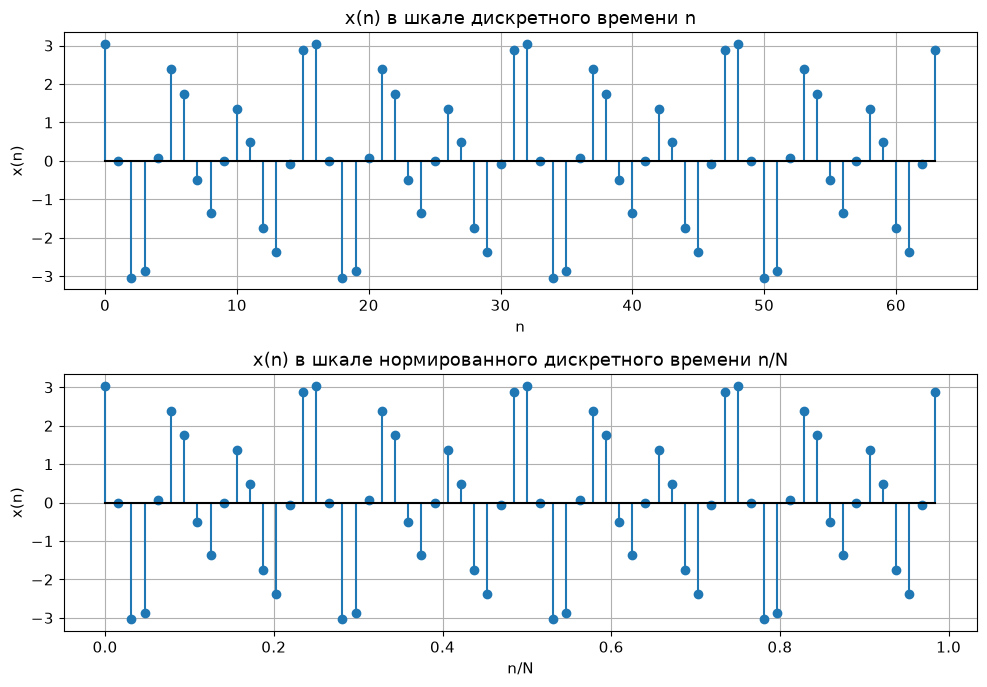

In [ ]:
n = np.arange(N)
t_norm = n / N  # нормированное дискретное время n/N

x_per = A1 * np.cos(2 * np.pi * f1 * n * T + np.pi / 4) + A2 * np.cos(2 * np.pi * f2 * n * T + np.pi / 8)

# N действительно является периодом: на N отсчётах каждая гармоника укладывается целое число раз
cycles1, cycles2 = f1 * N * T, f2 * N * T
assert np.isclose(cycles1, round(cycles1)) and np.isclose(cycles2, round(cycles2))

fig, axes = plt.subplots(2, 1, figsize=(10, 7))
axes[0].stem(n, x_per, basefmt="k-")
axes[0].set_title("x(n) в шкале дискретного времени n")
axes[0].set_xlabel("n"); axes[0].set_ylabel("x(n)"); axes[0].grid(True)
axes[1].stem(t_norm, x_per, basefmt="k-")
axes[1].set_title("x(n) в шкале нормированного дискретного времени n/N")
axes[1].set_xlabel("n/N"); axes[1].set_ylabel("x(n)"); axes[1].grid(True)
plt.tight_layout(); plt.show()

На рисунке один и тот же сигнал показан в двух шкалах времени; меняется только подпись и масштаб оси $x$, значения $x$ остаются прежними.

* **Дискретное время** $n = 0, \dots, 63$ — номера отсчётов.
* **Дискретное нормированное время** $\hat n = n/N$ — доля периода; ось $0 \dots 1$ соответствует одному периоду и не зависит ни от $N$, ни от $f_д$ (шаг $1/N = 0.01562$). Связь: $\hat n = n/N$, $n = \hat n N$.

### Пункт 2.2. Обратное ДПФ от ДПФ последовательности

Максимальная ошибка восстановления:        4.996e-16


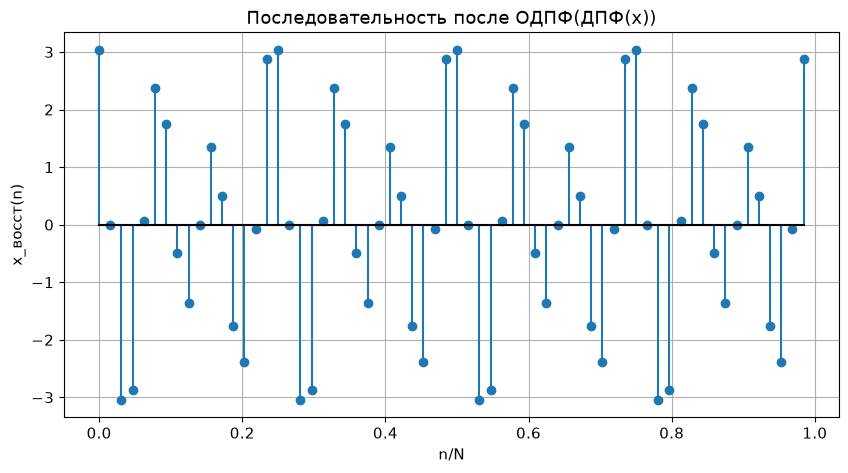

In [ ]:
X = np.fft.fft(x_per)   # прямое ДПФ
x_rec = np.fft.ifft(X)  # ОДПФ

err_idft = np.max(np.abs(x_rec.real - x_per))
print(f"Максимальная ошибка восстановления:        {err_idft:.3e}")
assert np.allclose(x_rec.real, x_per, atol=1e-12)

plt.figure()
plt.stem(t_norm, x_rec.real, basefmt="k-")
plt.title("Последовательность после ОДПФ(ДПФ(x))")
plt.xlabel("n/N"); plt.ylabel("x_восст(n)"); plt.grid(True)
plt.show()

ДПФ и ОДПФ — взаимно обратные преобразования: ДПФ раскладывает последовательность на гармоники, ОДПФ собирает её обратно по амплитудам и фазам. График восстановленной последовательности совпадает с графиком $x(n)$ из п. 2.1; максимальная ошибка равна $5.00e-16$ — это погрешность округления чисел с плавающей точкой. Информация о сигнале при прямом и обратном преобразованиях не теряется.

### Пункт 2.3. Амплитудный и фазовый спектры

Спектры построены в шкалах дискретных нормированных частот $\hat\omega = 2\pi k/N$ и абсолютных частот $f_k = k f_д/N$. Фаза показана только там, где амплитуда отлична от нуля (в остальных точках фаза не имеет смысла и определяется шумом округления).

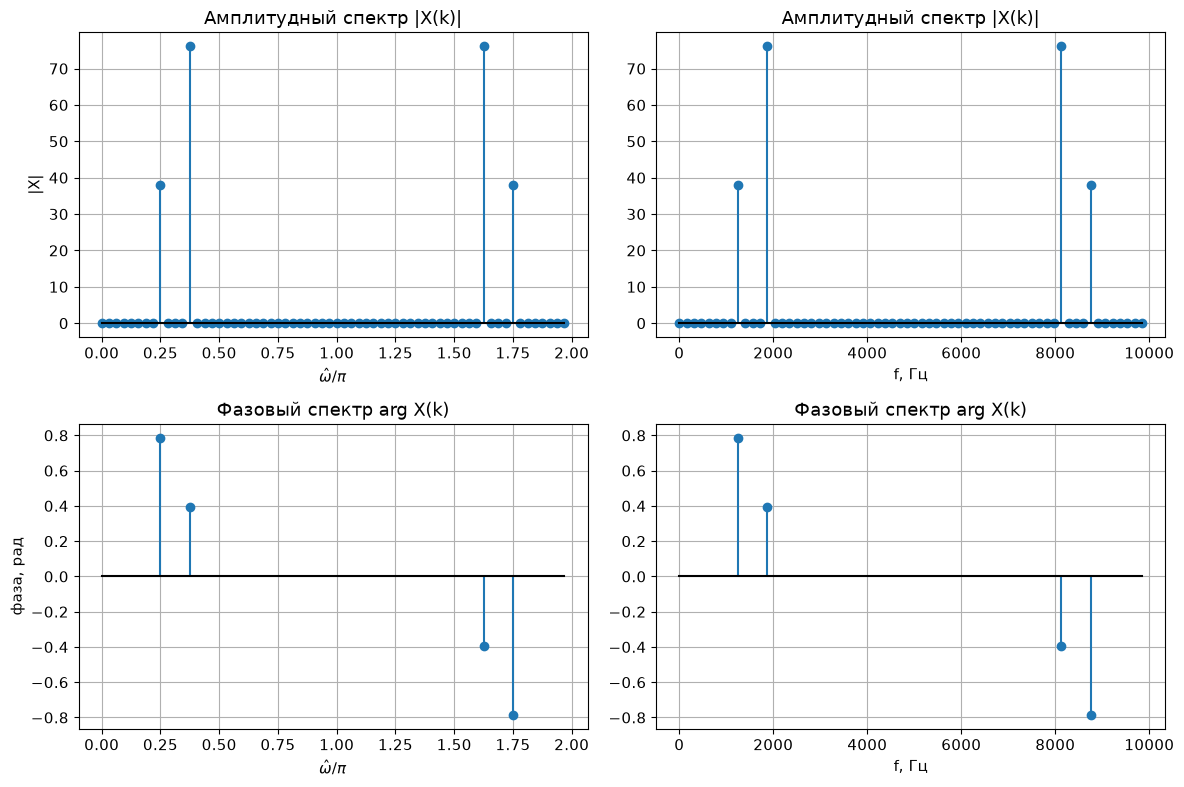

 k    f, Гц     ω/π     |X(k)|   |X|/N   фаза, рад   фаза/π
 8   1250.0  0.2500   38.0800  0.5950    +0.7854  +0.2500
12   1875.0  0.3750   76.1600  1.1900    +0.3927  +0.1250
52   8125.0  1.6250   76.1600  1.1900    -0.3927  -0.1250
56   8750.0  1.7500   38.0800  0.5950    -0.7854  -0.2500


In [103]:
k = np.arange(N)
omega_k = 2 * np.pi * k / N
f_k = k * fd2 / N

X_mag = np.abs(X)
X_phase = np.angle(X)
mask = X_mag > 1e-9
phase_plot = np.where(mask, X_phase, np.nan)

scales = [(omega_k / np.pi, r"$\hat\omega / \pi$"), (f_k, "f, Гц")]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for j, (xs, lab) in enumerate(scales):
    axes[0, j].stem(xs, X_mag, basefmt="k-")
    axes[0, j].set_title("Амплитудный спектр |X(k)|"); axes[0, j].set_xlabel(lab); axes[0, j].grid(True)
    axes[1, j].stem(xs, phase_plot, basefmt="k-")
    axes[1, j].set_title("Фазовый спектр arg X(k)"); axes[1, j].set_xlabel(lab); axes[1, j].grid(True)
axes[0, 0].set_ylabel("|X|"); axes[1, 0].set_ylabel("фаза, рад")
plt.tight_layout(); plt.show()

nz = np.flatnonzero(mask)
print(" k    f, Гц     ω/π     |X(k)|   |X|/N   фаза, рад   фаза/π")
for p in nz:
    print(f"{p:2d}  {f_k[p]:7.1f}  {omega_k[p]/np.pi:6.4f}  {X_mag[p]:8.4f}  {X_mag[p]/N:6.4f}  {X_phase[p]:+9.4f}  {X_phase[p]/np.pi:+7.4f}")

# проверки: положительные частоты k1, k2
k1, k2 = int(round(f1 * N / fd2)), int(round(f2 * N / fd2))
assert np.array_equal(nz, [k1, k2, N - k2, N - k1])
assert np.isclose(X_mag[k1], A1 * N / 2) and np.isclose(X_mag[k2], A2 * N / 2)
assert np.isclose(X_phase[k1], np.pi / 4) and np.isclose(X_phase[k2], np.pi / 8)

**а) Связь дискретного нормированного времени с дискретным:** $\hat n = n/N$ (см. п. 2.1) — при переходе к $\hat n$ меняется только масштаб оси, а номер отсчёта $n$ и значения $x$ остаются прежними.

**б) Связь частоты $f$ (Гц) с дискретной нормированной частотой:** $\hat\omega = 2\pi f/f_д = 2\pi k/N$, поэтому $f = \dfrac{k}{N} f_д$. Один шаг по $k$ соответствует $f_д/N = 156.25$ Гц, полная ось $k = 0 \dots N-1$ — одному периоду спектра $[0, f_д)$.

**в) Вид амплитудного спектра.** Он содержит четыре ненулевые линии:
* $k = 8$ ($f = 1250$ Гц, $\hat\omega = 0.250\pi$): $|X| = 38.08 = A_1N/2$;
* $k = 12$ ($f = 1875$ Гц, $\hat\omega = 0.375\pi$): $|X| = 76.16 = A_2N/2$;
* зеркальные линии $k = 52$ и $k = 56$ ($f = 8125$ и $8750$ Гц) — следствие симметрии ДПФ вещественного сигнала, $X(N-k) = X^*(k)$; ось симметрии — $f_д/2 = 5000$ Гц.

Множитель $N/2$ возникает потому, что косинус $A\cos(\cdot)$ раскладывается на две комплексные экспоненты с амплитудами $A/2$, а ДПФ даёт ещё множитель $N$.

**Вид фазового спектра.** На положительных частотах фазы равны $0.7854$ рад $= \pi/4$ и $0.3927$ рад $= \pi/8$, то есть совпадают с начальными фазами гармоник; на зеркальных частотах знак фазы противоположный.

### Пункт 2.4. ДПФ конечной последовательности и амплитудный спектр периодической

ДПФ конечного блока длины $N$ даёт $X(k)$. Для периодического продолжения этого блока коэффициенты ряда Фурье равны $C(k) = X(k)/N$. Оба спектра построены в общей шкале нормированных частот $\hat\omega \in [-\pi, \pi)$.

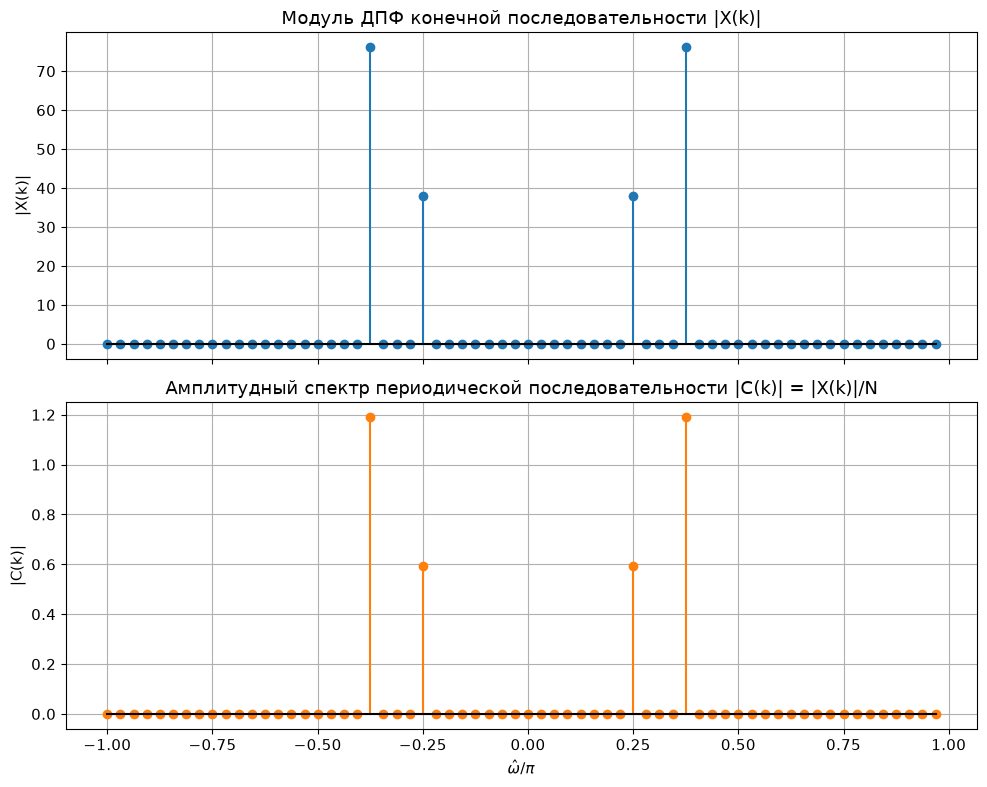

k:         [-12  -8   8  12]
|X(k)|:    [76.16 38.08 38.08 76.16]
|C(k)|:    [1.19  0.595 0.595 1.19 ]


In [ ]:
X_fin = np.fft.fft(x_per)   # ДПФ конечной последовательности
C = X_fin / N   # коэффициенты ряда Фурье периодической последовательности

k_c = np.fft.fftshift(np.fft.fftfreq(N) * N).astype(int)    # k = -N/2 ... N/2-1
omega_c = 2 * np.pi * k_c / N
mag_fin = np.fft.fftshift(np.abs(X_fin))
mag_per = np.fft.fftshift(np.abs(C))

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
axes[0].stem(omega_c / np.pi, mag_fin, basefmt="k-")
axes[0].set_title("Модуль ДПФ конечной последовательности |X(k)|"); axes[0].set_ylabel("|X(k)|"); axes[0].grid(True)
axes[1].stem(omega_c / np.pi, mag_per, basefmt="k-", linefmt="C1-", markerfmt="C1o")
axes[1].set_title("Амплитудный спектр периодической последовательности |C(k)| = |X(k)|/N")
axes[1].set_xlabel(r"$\hat\omega / \pi$"); axes[1].set_ylabel("|C(k)|"); axes[1].grid(True)
plt.tight_layout(); plt.show()

nzc = np.flatnonzero(mag_per > 1e-9)
print("k:        ", k_c[nzc])
print("|X(k)|:   ", np.round(mag_fin[nzc], 4))
print("|C(k)|:   ", np.round(mag_per[nzc], 4))
assert np.allclose(mag_fin, N * mag_per)
assert np.allclose(mag_per[nzc], [A2 / 2, A1 / 2, A1 / 2, A2 / 2])

Графики имеют одинаковый вид и положение линий ($k = \pm 8,\ \pm 12$); значения различаются ровно в $N = 64$ раз: $|X(k)| = N\,|C(k)|$. Так, $|X| = 38.08$ и $76.16$ соответствуют $|C| = 0.60$ и $1.19$ (то есть $A_1/2$ и $A_2/2$ на каждую из пары частот $\pm f$).

Совпадение формы спектров объясняется тем, что обе гармоники укладываются в блок целое число раз (на частотах, кратных $f_д/N$). В этом случае периодическое продолжение блока не имеет разрывов, спектральной утечки («растекания») нет, и ДПФ блока точно воспроизводит линейчатый спектр периодического сигнала.

### Пункт 2.5. Восстановление периодического аналогового сигнала

Сигнал восстанавливается по ДПФ на интервале $0 \le t \le (N-1)T$ с шагом $\Delta t = 0.25T$ по формуле ряда Фурье из теоретической части (сдвиг индексов $X_a$ реализован через `fftshift`: порядок $k = -N/2, \dots, N/2-1$ совпадает с $X(N+k)$ при $k < 0$ и $X(k)$ при $k \ge 0$). Амплитудный спектр восстановленного сигнала считается по одному полному периоду $NT$ (шаг $T/4$, $4N$ точек): на интервале $[0; (N-1)T]$ целое число периодов не укладывается, и спектр там был бы искажён утечкой.

Число точек: 253, последняя t = 6.3000 мс = (N-1)T
Макс. |x_восст(t) - x_исх(t)|: 4.152e-14
Макс. |Im x_восст(t)|:          4.204e-16


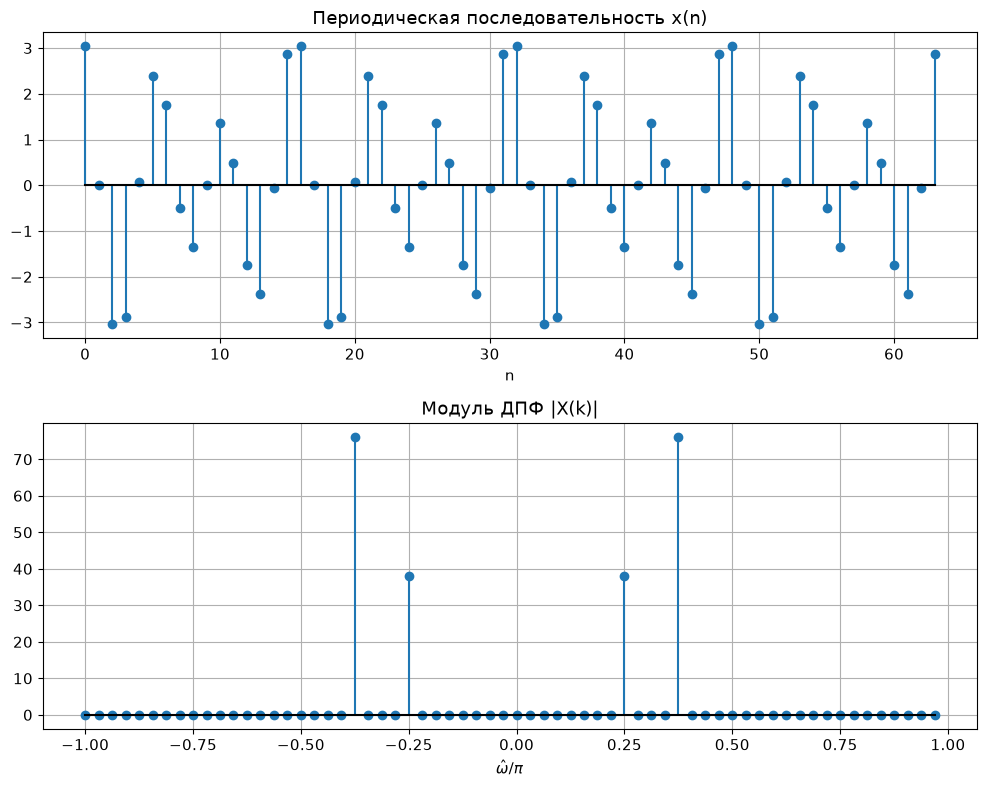

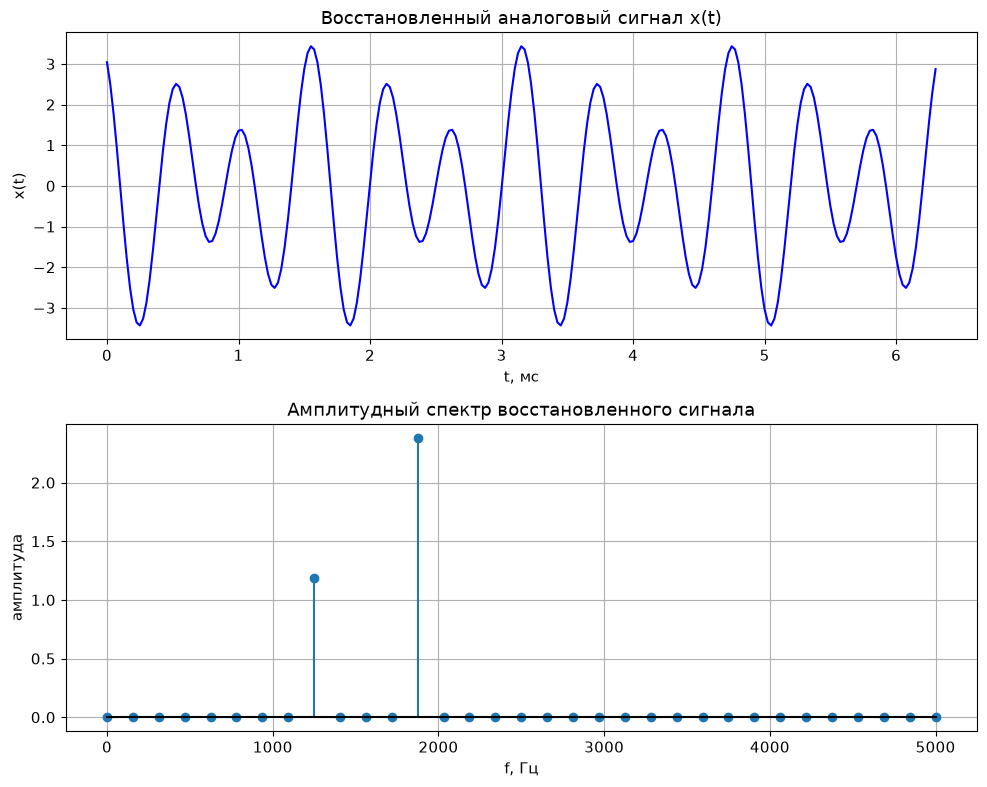

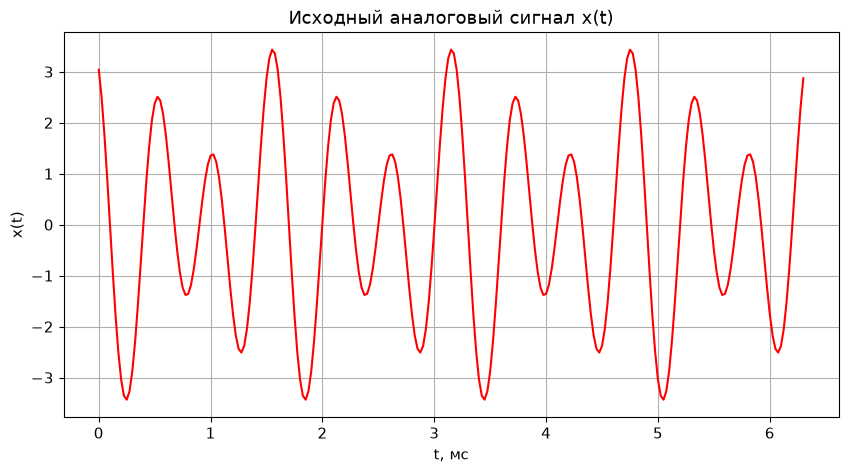

Пики спектра восстановленного сигнала (f, Гц : амплитуда):
    1250.0 : 1.1900
    1875.0 : 2.3800


In [ ]:
k_idx = np.fft.fftshift(np.fft.fftfreq(N) * N).astype(int)   # -N/2 ... N/2-1
X_a = np.fft.fftshift(X)                                     # X_a(k)

def reconstruct(t):
    """x(t) = (1/N) * sum_k X_a(k) exp(j 2π k t / (N T))."""
    basis = np.exp(1j * 2 * np.pi * np.outer(t, k_idx) / (N * T))
    return (basis @ X_a) / N

def analog_original(t):
    return A1 * np.cos(2 * np.pi * f1 * t + np.pi / 4) + A2 * np.cos(2 * np.pi * f2 * t + np.pi / 8)

dt = 0.25 * T
t_an = np.arange(4 * (N - 1) + 1) * dt                # 0 ... (N-1)T, шаг T/4
x_rec_an = reconstruct(t_an)
x_orig_an = analog_original(t_an)

err_an = np.max(np.abs(x_rec_an.real - x_orig_an))
imag_an = np.max(np.abs(x_rec_an.imag))
print(f"Число точек: {len(t_an)}, последняя t = {t_an[-1]*1e3:.4f} мс = (N-1)T")
print(f"Макс. |x_восст(t) - x_исх(t)|: {err_an:.3e}")
print(f"Макс. |Im x_восст(t)|:          {imag_an:.3e}")
assert err_an < 1e-10 and imag_an < 1e-10

# Спектр восстановленного сигнала: берём ровно один период (N·T), шаг T/4 -> целое число периодов, утечки нет
t_per = np.arange(4 * N) * dt
x_per_an = reconstruct(t_per).real
S = np.fft.rfft(x_per_an) / len(x_per_an)
f_S = np.fft.rfftfreq(len(x_per_an), d=dt)
amp_S = 2 * np.abs(S); amp_S[0] /= 2

# а) последовательность и модуль её ДПФ
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].stem(n, x_per, basefmt="k-"); axes[0].set_title("Периодическая последовательность x(n)")
axes[0].set_xlabel("n"); axes[0].grid(True)
axes[1].stem(omega_c / np.pi, np.abs(X_a), basefmt="k-"); axes[1].set_title("Модуль ДПФ |X(k)|")
axes[1].set_xlabel(r"$\hat\omega / \pi$"); axes[1].grid(True)
plt.tight_layout(); plt.show()

# б) восстановленный сигнал и его амплитудный спектр
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].plot(t_an * 1e3, x_rec_an.real, "b-")
axes[0].set_title("Восстановленный аналоговый сигнал x(t)")
axes[0].set_xlabel("t, мс"); axes[0].set_ylabel("x(t)"); axes[0].grid(True)
axes[1].stem(f_S[f_S <= fd2 / 2], amp_S[f_S <= fd2 / 2], basefmt="k-")
axes[1].set_title("Амплитудный спектр восстановленного сигнала")
axes[1].set_xlabel("f, Гц"); axes[1].set_ylabel("амплитуда"); axes[1].grid(True)
plt.tight_layout(); plt.show()

# в) исходный аналоговый сигнал x(t) = x(nT) при nT = t
plt.figure()
plt.plot(t_an * 1e3, x_orig_an, "r-")
plt.title("Исходный аналоговый сигнал x(t)")
plt.xlabel("t, мс"); plt.ylabel("x(t)"); plt.grid(True)
plt.show()

pk = np.flatnonzero(amp_S > 1e-6)
print("Пики спектра восстановленного сигнала (f, Гц : амплитуда):")
for p in pk:
    print(f"  {f_S[p]:8.1f} : {amp_S[p]:.4f}")
assert np.allclose(f_S[pk], [f1, f2]) and np.allclose(amp_S[pk], [A1, A2])

### Пункт 2.6. Анализ результатов восстановления

**а) Связь модуля ДПФ со спектром аналогового сигнала.** В спектре восстановленного сигнала две линии: $1250$ Гц с амплитудой $1.19$ и $1875$ Гц с амплитудой $2.38$ — это в точности $A_1$ и $A_2$. Они соответствуют отсчётам ДПФ $k = \pm 8$ и $k = \pm 12$. Для положительной частоты амплитуда гармоники связана с модулем ДПФ формулой $A = 2|X(k)|/N$: $2\cdot 38.08/64 = 1.19$, $2\cdot 76.16/64 = 2.38$. В двустороннем спектре модуль каждой отдельной линии равен $|X(k)|/N$, то есть половине амплитуды косинуса.

**б) Сравнение восстановленного и исходного сигналов.** Графики восстановленного и исходного сигналов визуально неотличимы: максимальное различие на интервале $4.2e-14$ (погрешность вычислений с плавающей точкой), мнимая часть $4.2e-16$. Точное восстановление возможно, потому что (1) условие Котельникова выполнено: $f_д = 10000$ Гц $> 2f_2 = 3750$ Гц; (2) обе гармоники точно попадают в узлы ДПФ, а ряд Фурье содержит все их коэффициенты, так что между отсчётами сигнал восстанавливается без искажений.

### Пункт 2.7. Проверка равенства Парсеваля

In [106]:
E_time = np.sum(np.abs(x_per) ** 2)
E_freq = np.sum(np.abs(X) ** 2) / N

print(f"Энергия во времени:      Σ|x(n)|²        = {E_time:.9f}")
print(f"Энергия по спектру:      (1/N)·Σ|X(k)|²  = {E_freq:.9f}")
print(f"Абсолютная разность:     {abs(E_time - E_freq):.3e}")
print(f"Относительная разность:  {abs(E_time - E_freq) / E_time:.3e}")
assert np.isclose(E_time, E_freq, rtol=1e-12)

Энергия во времени:      Σ|x(n)|²        = 226.576000000
Энергия по спектру:      (1/N)·Σ|X(k)|²  = 226.576000000
Абсолютная разность:     0.000e+00
Относительная разность:  0.000e+00


**Равенство Парсеваля** — закон сохранения энергии при переходе во временную/частотную область:
$$\sum_{n=0}^{N-1}|x(n)|^2 = \frac{1}{N}\sum_{k=0}^{N-1}|X(k)|^2.$$

Результаты: $E_{время} = 226.576000$, $E_{спектр} = 226.576000$; абсолютная разность $0.0e+00$ (погрешность округления), то есть равенство выполняется.

Физический смысл: ДПФ только перераспределяет энергию между отсчётами во времени и спектральными линиями — полная энергия не теряется и не появляется (множитель $1/N$ — следствие принятого определения ДПФ без нормировки).

## Выводы

В работе изучены линейные дискретные системы и ДПФ; расчёты выполнены для варианта 19.

**Часть 1.**
1. Рекурсивное звено 2-го порядка имеет комплексно-сопряжённые полюсы $p_{1,2} = 0.8683\,e^{\pm j0.2435\pi}$ внутри единичной окружности ($|p| < 1$), поэтому оно устойчиво; импульсная характеристика бесконечна и затухает колебательно. Для неё получена и численно проверена аналитическая формула. Нули ($|z| = 1.2649$) лежат вне окружности, поэтому АЧХ нигде не равна нулю.
2. Реакция по свёртке с усечённой до $N_1 = 29$ отсчётов характеристикой $y_1$ совпадает с реакцией по разностному уравнению $y_2$ при $n < N_1$; далее расхождение достигает $0.154$ из-за усечения $h(n)$. При достаточной длине $h$ расхождение равно $3e-15$, то есть оба способа эквивалентны.
3. АЧХ — резонансная, типа фильтра нижних частот: максимум $16.79$ на $f \approx 2251$ Гц (определяется полюсами), минимум $0.202$ на $f \approx 6581$ Гц (определяется нулями); составляющие выше $\approx 4752$ Гц ослабляются.

**Часть 2.**
1. Прямое и обратное ДПФ взаимно обратны: ошибка восстановления $5.0e-16$.
2. Амплитудный и фазовый спектры дают линии на $f_1 = 1250$ Гц и $f_2 = 1875$ Гц (и зеркальных) с амплитудами $A N/2$ и фазами $\pi/4$, $\pi/8$. Модуль ДПФ блока равен $N|C(k)|$ — утечки нет, поскольку гармоники кратны $f_д/N$.
3. Аналоговый сигнал, восстановленный по $N = 64$ отсчётам ДПФ, совпадает с исходным (ошибка $4.2e-14$); спектр восстановленного сигнала содержит гармоники с амплитудами $A_1 = 1.19$ и $A_2 = 2.38$.
4. Равенство Парсеваля выполнено: $E = 226.576$ во временной и частотной областях.